Housing Dataset Loaded!
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  
Dataset Shape: (20640, 9)

REGRESSION MODEL RESULTS
   Model    RMSE     MAE  R2 Score
0    OLS  0.6753  0.4862    0.6519
1  Ridge  0.6754  0.4862    0.6519
2  Lasso  0.6757  0.4863    0.6516

Best Model: OLS


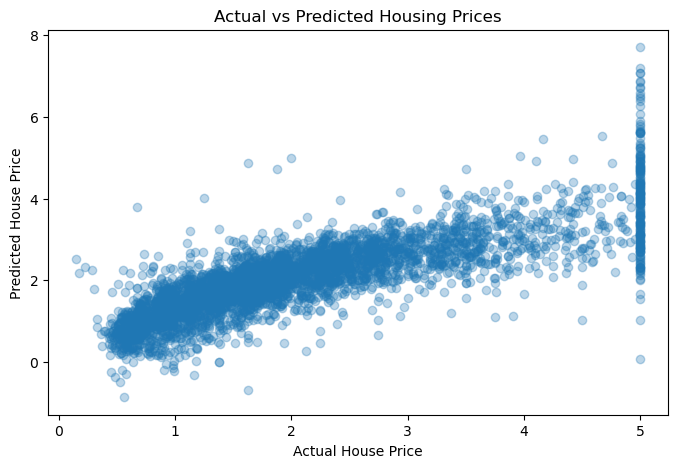

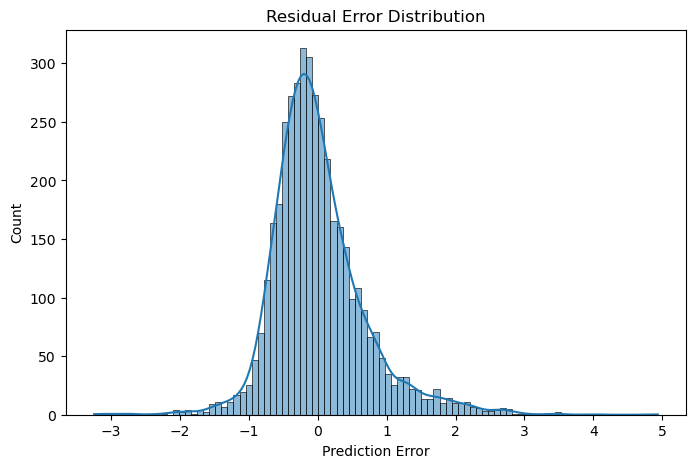


PROJECT COMPLETED SUCCESSFULLY!


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    Lasso
)
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

housing = fetch_california_housing(as_frame=True)
df = housing.frame
print("Housing Dataset Loaded!")
print(df.head())
print("Dataset Shape:", df.shape)
df.to_csv("california_housing.csv", index=False)

X = df.drop("MedHouseVal", axis=1)
y = df["MedHouseVal"]
X = X.copy()

X["RoomsPerPerson"] = (
    X["AveRooms"] / X["AveOccup"].replace(0, np.nan)
)
X["BedroomsPerRoom"] = (
    X["AveBedrms"] / X["AveRooms"].replace(0, np.nan)
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

models = {
    "OLS": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=0.001, max_iter=10000)
}

results = []
predictions = {}

for name, model in models.items():
    pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", model)
    ])
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    predictions[name] = y_pred
    rmse = np.sqrt(
        mean_squared_error(y_test, y_pred)
    )
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    results.append([
        name, rmse, mae, r2
    ])

result_df = pd.DataFrame(
    results,
    columns=["Model", "RMSE", "MAE", "R2 Score"]
)

print("\nREGRESSION MODEL RESULTS")
print(result_df.round(4))

best_model_name = result_df.sort_values(
    "RMSE"
).iloc[0]["Model"]
y_pred = predictions[best_model_name]
print("\nBest Model:", best_model_name)

plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, alpha=0.3)
plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.title("Actual vs Predicted Housing Prices")
plt.show()

residuals = y_test - y_pred
plt.figure(figsize=(8, 5))
sns.histplot(residuals, kde=True)
plt.title("Residual Error Distribution")
plt.xlabel("Prediction Error")
plt.show()
print("\nPROJECT COMPLETED SUCCESSFULLY!")